# QIS meets gravity: Hawking radiation, black-hole entropy, and the Page curve
### every formula derived in SymPy, and the information paradox simulated with qubits

**In plain words.** In 1974 Hawking showed that black holes glow with a temperature set by their
mass, so they slowly evaporate. Their entropy is a quarter of their horizon area: a count of
**bits** written on the surface. If evaporation obeys quantum mechanics (unitarity), those bits
must eventually come back out in the radiation. Page computed what that requires; Hawking's
original calculation says otherwise. That conflict is the **information paradox**, and quantum
information theory is how physicists now argue about it.

**Two kinds of reasoning in this notebook:**
* **SymPy derivations:** §1–§4 are exact algebra and calculus that you can check line by line.
* **Qubit toy models:** §6–§7 use random states and random unitaries, the standard teaching
  device of Page (1993) and Hayden & Preskill (2007). They show the information-theoretic logic;
  they are not a theory of quantum gravity.

Every figure uses the Okabe–Ito colorblind-safe palette, distinguishes curves by line style and
marker as well as color, and has a printed text description.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sympy as sp
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import hawking_qis as h
from dgs.hawking_qis import Gs, Ms, cs, hb, kB
sp.init_printing()
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)

## 1. Surface gravity from the metric

The Schwarzschild metric has $f(r)=1-r_s/r$ with $r_s=2GM/c^2$. The **surface gravity**, which is
the acceleration at the horizon as measured from infinity, is $\kappa=\tfrac{c^2}{2}f'(r_s)$:

In [2]:
sp.Eq(sp.Symbol("kappa"), h.surface_gravity_symbolic())

## 2. Temperature from geometry: the Euclidean trick

Replace $t\to-i\tau$, which turns time into an angle-like coordinate. Near the horizon put
$r=r_s+x$ and keep first order, $f\approx f'(r_s)\,x$. Using the proper distance
$\rho=\int dx/\sqrt f$, the metric becomes

$$ds^2=\Big(\tfrac{c\,f'(r_s)}{2}\Big)^2\rho^2\,d\tau^2+d\rho^2 .$$

That's flat polar coordinates $\rho^2d\theta^2+d\rho^2$, with angle $\theta=\tfrac{cf'}{2}\tau$.
To avoid a cone tip at $\rho=0$, the angle must have period $2\pi$, so $\tau$ has period $\beta$.
In quantum statistical mechanics, a period $\beta$ in imaginary time **is** a temperature,
$T=\hbar/(k_B\beta)$.

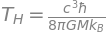

In [3]:
rho, coeff, beta = h.euclidean_period_symbolic()
display(sp.Eq(sp.Symbol("rho"), rho), sp.Eq(sp.Symbol("angular coefficient"), coeff), sp.Eq(sp.Symbol("beta"), beta))
T_H = h.hawking_temperature_symbolic()
sp.Eq(sp.Symbol("T_H"), T_H)

This is Hawking's formula, obtained with nothing but smoothness of a geometry. It is also the
**Unruh temperature** $T_U=\hbar a/(2\pi ck_B)$ evaluated at $a=\kappa$:

In [4]:
a = sp.symbols("a", positive=True)
sp.simplify(h.unruh_temperature_symbolic().subs(a, h.surface_gravity_symbolic()) - T_H)

## 3. Entropy from the first law, counted in bits

For a black hole, $d(Mc^2)=T\,dS$. Integrate $dS=c^2dM/T_H$ from 0 to $M$:

In [5]:
S, bh, diff = h.entropy_from_first_law()
display(sp.Eq(sp.Symbol("S (first law)"), S), sp.Eq(sp.Symbol("k_B c^3 A / (4 G hbar)"), bh)); print("difference:", diff)

difference: 0


So $S=k_Bc^3A/(4G\hbar)$: one quarter of the horizon area in Planck units. Dividing by
$k_B\ln2$ turns it into **bits**. A black hole is the densest possible hard drive, and the
**holographic bound** says no region can hold more information than a black hole of the same size.

In [6]:
for name, M in [("1 kg", 1.0), ("Moon", 7.35e22), ("Sun", h.M_SUN), ("Sgr A* (4.3e6 Msun)", 4.3e6 * h.M_SUN)]:
    print(f"{name:20s} r_s = {h.schwarzschild_radius(M):9.3e} m   T_H = {h.hawking_temperature(M):9.3e} K   S = {h.entropy_bits(M):9.3e} bits")
print(f"\nholographic limit of a 1 m sphere: {h.holographic_bits(1.0):.2e} bits")

1 kg                 r_s = 1.485e-27 m   T_H = 1.227e+23 K   S = 3.827e+16 bits
Moon                 r_s = 1.092e-04 m   T_H = 1.669e+00 K   S = 2.068e+62 bits
Sun                  r_s = 2.954e+03 m   T_H = 6.169e-08 K   S = 1.514e+77 bits
Sgr A* (4.3e6 Msun)  r_s = 1.270e+10 m   T_H = 1.435e-14 K   S = 2.799e+90 bits

holographic limit of a 1 m sphere: 1.74e+70 bits


## 4. Evaporation

Treat the horizon as a blackbody that emits photons only, ignoring greybody factors and other
particle species. Then $dM/dt=-\sigma AT^4/c^2$. SymPy derives the rate and integrates it to get
the lifetime:

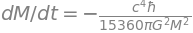

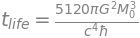

In [7]:
dMdt, life = h.evaporation_symbolic()
display(sp.Eq(sp.Symbol("dM/dt"), dMdt), sp.Eq(sp.Symbol("t_life"), life))

Sun: lifetime 2.10e+67 yr  (universe is 1.38e10 yr)
mass evaporating in 13.8 Gyr (photons only): 1.73e+11 kg
mass hotter than the CMB (2.725 K): below 4.50e+22 kg  (~0.6 Moon masses)
Unruh: acceleration to feel 1 K = 2.47e+20 m/s^2


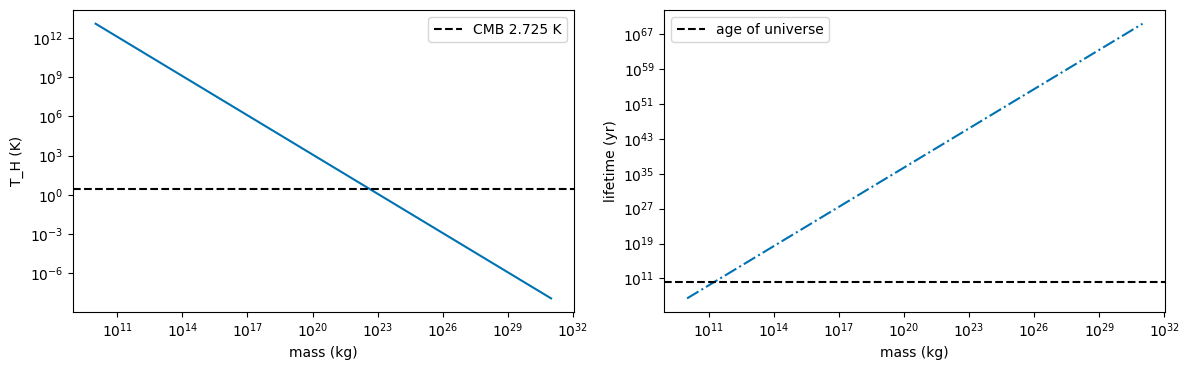

Figure description: left, Hawking temperature falls as 1/M, crossing the dashed CMB line near 4.5e22 kg. Right, lifetime rises as M^3, crossing the dashed age-of-universe line near 1.7e11 kg.


In [8]:
print(f"Sun: lifetime {h.lifetime_s(h.M_SUN)/h.YEAR:.2e} yr  (universe is 1.38e10 yr)")
print(f"mass evaporating in 13.8 Gyr (photons only): {h.mass_for_lifetime(13.8e9*h.YEAR):.2e} kg")
print(f"mass hotter than the CMB (2.725 K): below {h.mass_for_temperature(2.725):.2e} kg  (~0.6 Moon masses)")
print(f"Unruh: acceleration to feel 1 K = {h.unruh_acceleration_for(1.0):.2e} m/s^2")
M = np.logspace(10, 31, 200)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].loglog(M, h.hawking_temperature(M)); ax[0].axhline(2.725, ls="--", c="k", label="CMB 2.725 K")
ax[0].set_xlabel("mass (kg)"); ax[0].set_ylabel("T_H (K)"); ax[0].legend()
ax[1].loglog(M, h.lifetime_s(M) / h.YEAR, ls="-."); ax[1].axhline(1.38e10, ls="--", c="k", label="age of universe")
ax[1].set_xlabel("mass (kg)"); ax[1].set_ylabel("lifetime (yr)"); ax[1].legend(); plt.tight_layout(); plt.show()
print("Figure description: left, Hawking temperature falls as 1/M, crossing the dashed CMB line near 4.5e22 kg. "
      "Right, lifetime rises as M^3, crossing the dashed age-of-universe line near 1.7e11 kg.")

Stellar-mass black holes are colder than the cosmic microwave background, so today they
absorb more than they emit. Only hypothetical small primordial black holes would be evaporating
now. The photon-only estimate is a lower bound on that mass: including more particle species
makes evaporation faster and raises it.

## 5. The paradox, stated in information terms

* Hawking radiation is produced in **entangled pairs** at the horizon: one partner escapes, the other falls in.
* Semiclassically, every outgoing quantum is entangled with the interior, so the radiation's
  entanglement entropy **keeps rising**, by one bit per emitted qubit.
* But a black hole holds only $S_{BH}$ bits. Once more than half has radiated, the radiation can't
  be entangled with an interior that is smaller than itself, if the whole process is a unitary
  (pure-state) evolution.
* Unitarity therefore requires the curve to **turn over**: the Page curve.

## 6. The Page curve with real qubits

Model the black hole plus radiation as a random pure state of $N$ qubits. After $k$ qubits have
been "emitted", the radiation's entropy is the entanglement entropy of the first $k$ qubits,
computed exactly from an SVD (Schmidt decomposition). Page's exact formula
$S\approx\sum_{j=n+1}^{mn}\tfrac1j-\tfrac{m-1}{2n}$ (in nats, with $m\le n$) is overlaid.

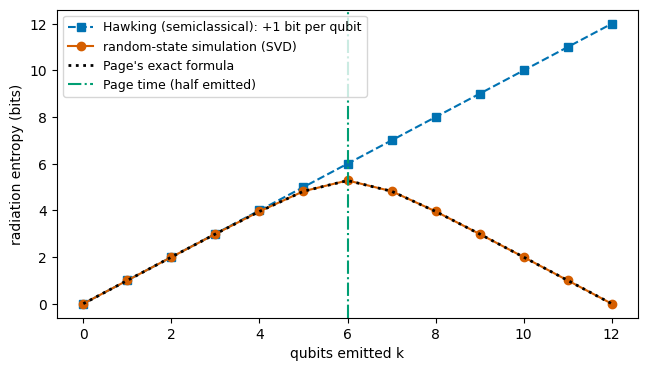

max |sim - Page| = 0.003 bits
Figure description: the semiclassical curve (squares, dashed) rises linearly to 12 bits. The simulated curve (circles, solid) and Page's formula (dotted) rise, peak at k = 6, and fall back to zero.


In [9]:
k, sim, page, hawking = h.page_curve(n_total=12, n_samples=20)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(k, hawking, "s--", label="Hawking (semiclassical): +1 bit per qubit")
ax.plot(k, sim, "o-", label="random-state simulation (SVD)")
ax.plot(k, page, "k:", lw=2, label="Page's exact formula")
ax.axvline(6, ls="-.", c=OI[2], label="Page time (half emitted)")
ax.set_xlabel("qubits emitted k"); ax.set_ylabel("radiation entropy (bits)"); ax.legend(fontsize=9); plt.show()
print("max |sim - Page| =", round(float(np.max(np.abs(sim - page))), 3), "bits")
print("Figure description: the semiclassical curve (squares, dashed) rises linearly to 12 bits. The simulated "
      "curve (circles, solid) and Page's formula (dotted) rise, peak at k = 6, and fall back to zero.")

The turnover at the **Page time** is the signature of unitarity. In 2019, semiclassical
gravity calculations that include "islands" and replica wormholes reproduced this curve, a major
recent result. The qubit model above shows only *what* curve unitarity demands, not *how* gravity
produces it.

## 7. Hayden–Preskill: black holes as mirrors

Alice throws a one-qubit "diary" $D$ into an **old** black hole, one already past its Page time
and maximally entangled with its early radiation $E$. A reference qubit $R$ stays entangled
with the diary, so we can track where the information goes. A random unitary scrambles the
diary into the hole, and then $k$ qubits come out. The diary is recoverable from the radiation
when the mutual information $I(R:E\cup\text{emitted})$ reaches 2 bits, its maximum.

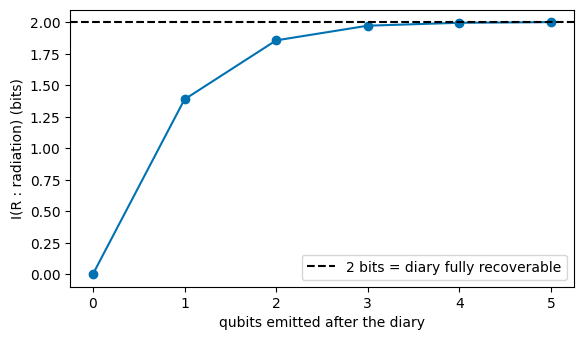

[0.    1.386 1.855 1.971 1.994 1.999]
Figure description: mutual information starts at 0, jumps to about 1.4 bits after one emitted qubit, and approaches the dashed 2-bit line within three qubits.


In [10]:
kk, I = h.hayden_preskill(n_bh=5, n_emit_max=5)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(kk, I, "o-"); ax.axhline(2, ls="--", c="k", label="2 bits = diary fully recoverable")
ax.set_xlabel("qubits emitted after the diary"); ax.set_ylabel("I(R : radiation) (bits)"); ax.legend(); plt.show()
print(np.round(I, 3))
print("Figure description: mutual information starts at 0, jumps to about 1.4 bits after one emitted qubit, "
      "and approaches the dashed 2-bit line within three qubits.")

The information comes back out after only a few qubits, not after the whole hole evaporates.
A scrambled old black hole behaves like an information mirror. This result connects black holes
to quantum error correction and to the study of fast scrambling in quantum computers.

## 8. Why the Department of Defense cares about QIS, 2002–2026

The black-hole questions are pure science. The **same toolkit** (entanglement entropy, random
unitaries, error correction, decoherence) underlies quantum computing, communication and
sensing. Those three areas sit on the US defense research agenda. The milestones below are
public, well-documented ones; verify the details against primary sources before citing them:

In [11]:
for y, what, kind in h.QIS_TIMELINE:
    print(f"{y}  [{kind:10s}]  {what}")

2002  [roadmap   ]  ARDA-sponsored Quantum Information Science and Technology Roadmap (v1, LANL-led)
2004  [roadmap   ]  QIST Roadmap version 2
2018  [law       ]  National Quantum Initiative Act signed (December)
2022  [DoD policy]  USD(R&E) critical technology areas list names quantum science
2022  [policy    ]  NSM-10: national security memo on quantum computing and migration to post-quantum cryptography
2022  [DARPA     ]  DARPA US2QC: underexplored systems for utility-scale quantum computing
2024  [standards ]  NIST publishes first post-quantum cryptography standards (FIPS 203, 204, 205)
2024  [DARPA     ]  DARPA Quantum Benchmarking Initiative announced


Gravity and QIS meet in practice through **quantum sensing**. Atom-interferometer
gravimeters and accelerometers measure the gravitational field with matter waves. Navigation
without GPS is a widely stated defense motivation for them. The interferometer phase is
retrieved from intensity fringes: the same phase-retrieval problem as dispersion-assisted GS in
this repo.

**Connections to the rest of the repo:**
* Entanglement entropy from an SVD is the same SVD used for PCA in ML.
* Random unitaries are random-matrix theory.
* Decoherence (`dgs.cell_hilbert_bridge`, `dgs.dephasing_phase_retrieval`) is what turns an
  evaporating hole's entangled radiation into apparently thermal noise for anyone who sees only part of it.

*Synthetic toy models; numbers use photon-only blackbody emission. Education.*